# Módulo 27: Clustering jerárquico

Autor: Juliho Castillo Colmenares

> Lección complementaria del ejercicio de este módulo: [enunciado](m27-clustering-jerarquico-guia.ipynb) y [solución](m27-clustering-jerarquico-solucion.ipynb). No es una tarea entregada del programa.

El **clustering** agrupa registros parecidos sin usar etiquetas: es aprendizaje no supervisado. El **clustering jerárquico** no entrega una sola partición, sino una jerarquía completa de agrupaciones que se dibuja como un árbol, el **dendrograma**. Después se elige a qué altura cortarlo. En esta lección se segmenta a un grupo de clientes y se usan los segmentos para hacer recomendaciones:

1. Distancia euclidiana y estandarización
2. El algoritmo aglomerativo
3. Criterios de enlace
4. El dendrograma con SciPy
5. Cortar el dendrograma y elegir k
6. `AgglomerativeClustering` de scikit-learn
7. Comparar criterios de enlace
8. Perfil de los clústeres
9. Recomendar a partir de los clústeres
10. Errores frecuentes
11. Ejercicio

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

Se simulan 36 clientes de una tienda en línea, con su gasto mensual (en pesos) en tres categorías y su número de compras al mes. Hay tres segmentos ocultos: aficionados a la tecnología, lectores ocasionales y lectores frecuentes. Los dos últimos solo se distinguen por el número de compras.

In [2]:
rng = np.random.default_rng(42)
segmentos = {                      # tecnologia, libros, hogar, compras_mes
    "tecnologia": [800, 100, 300, 3],
    "lector_ocasional": [200, 400, 300, 3],
    "lector_frecuente": [200, 400, 300, 12],
}
ruido = [80, 50, 120, 1.5]         # desviación de cada variable dentro de un segmento

filas = []
for segmento, centro in segmentos.items():
    filas.append(pd.DataFrame(rng.normal(centro, ruido, size=(12, 4)),
                              columns=["tecnologia", "libros", "hogar", "compras_mes"])
                 .assign(segmento=segmento))
clientes = pd.concat(filas, ignore_index=True)
variables = ["tecnologia", "libros", "hogar", "compras_mes"]
clientes[variables] = clientes[variables].round(0).clip(lower=0)

nombres = ["Ana", "Bruno", "Carla", "Diego", "Elena", "Fabián", "Gina", "Hugo", "Irene",
           "Javier", "Karla", "Luis", "Marta", "Nico", "Olga", "Pablo", "Quique", "Rosa",
           "Sara", "Tomás", "Úrsula", "Víctor", "Wendy", "Ximena", "Yago", "Zoe", "Abril",
           "Beto", "Celia", "Dante", "Eva", "Félix", "Gael", "Hilda", "Iván", "Julia"]
clientes.index = nombres
clientes.head()

,tecnologia,libros,hogar,compras_mes,segmento
Ana,824.0,48.0,390.0,4.0,tecnologia
Bruno,644.0,35.0,315.0,3.0,tecnologia
Carla,799.0,57.0,406.0,4.0,tecnologia
Diego,805.0,156.0,356.0,2.0,tecnologia
Elena,830.0,52.0,405.0,3.0,tecnologia


## 1. Distancia euclidiana y estandarización

Para agrupar hace falta medir qué tan lejos están dos registros. La más común es la **distancia euclidiana**:

$$d(x, y) = \sqrt{\sum_{j=1}^{p} (x_j - y_j)^2}.$$

Cada variable aporta su diferencia al cuadrado, así que las variables con valores grandes dominan. Una diferencia de 100 pesos pesa mucho más que una de 9 compras, aunque las compras sean justo lo que separa a dos segmentos. Por eso se **estandariza** cada columna, $z = (x - \bar x)/s$, antes de calcular distancias.

In [3]:
print(clientes[variables].std().round(1))

Z_datos = StandardScaler().fit_transform(clientes[variables])

# Distancia entre una lectora ocasional y una lectora frecuente
i, j = nombres.index("Marta"), nombres.index("Abril")
print(f"Sin estandarizar: {np.linalg.norm(clientes[variables].values[i] - clientes[variables].values[j]):.1f}")
print(f"Estandarizado:    {np.linalg.norm(Z_datos[i] - Z_datos[j]):.2f}")
print(clientes.loc[["Marta", "Abril"], variables])

tecnologia     297.2
libros         156.0
hogar          118.9
compras_mes      4.4
dtype: float64
Sin estandarizar: 197.6
Estandarizado:    2.10
       tecnologia  libros  hogar  compras_mes
Marta       254.0   403.0  335.0          4.0
Abril       125.0   390.0  186.0         11.0


## 2. El algoritmo aglomerativo

El clustering jerárquico **aglomerativo** construye el árbol de abajo hacia arriba:

1. Cada registro empieza como un clúster propio.
2. Se unen los dos clústeres más cercanos.
3. Se recalculan las distancias del clúster nuevo al resto.
4. Se repite hasta que solo queda un clúster.

Con $n$ registros hay $n-1$ uniones. `scipy.cluster.hierarchy.linkage` las devuelve en una matriz de $n-1$ filas: los dos clústeres que se unen, la distancia a la que se unen y el tamaño del clúster resultante. Los índices $\ge n$ se refieren a clústeres creados en pasos anteriores.

In [4]:
puntos = np.array([[0, 0], [0, 1], [5, 5], [5, 6], [6, 5], [10, 0]])
Z_mini = linkage(puntos, method="single")

pd.DataFrame(Z_mini, columns=["clúster_a", "clúster_b", "distancia", "tamaño"]).astype(
    {"clúster_a": int, "clúster_b": int, "tamaño": int}).round(3)

,clúster_a,clúster_b,distancia,tamaño
0,0,1,1.000,2
1,2,3,1.000,2
2,4,7,1.000,3
3,6,8,6.403,5
4,5,9,6.403,6


Primero se unen los pares a distancia 1 (0 con 1 y 2 con 3); el clúster 7, formado por 2 y 3, recibe después al punto 4. El punto 5, aislado, se une al final.

## 3. Criterios de enlace

El paso 3 necesita definir la distancia entre dos **clústeres** $A$ y $B$. Esa regla es el **criterio de enlace**:

| Enlace | Distancia entre $A$ y $B$ | Comportamiento |
| --- | --- | --- |
| `single` | $\min_{a \in A,\, b \in B} d(a, b)$ | Encadena puntos; clústeres alargados |
| `complete` | $\max_{a \in A,\, b \in B} d(a, b)$ | Clústeres compactos; sensible a atípicos |
| `average` | $\frac{1}{\lvert A\rvert \lvert B\rvert} \sum_{a \in A} \sum_{b \in B} d(a, b)$ | Intermedio |
| `ward` | Incremento de la suma de cuadrados intra-clúster al unirlos | Clústeres de tamaño parecido |

Ward une el par que **menos aumenta** la suma de cuadrados dentro de los clústeres. Con centroides $\mu_A$, $\mu_B$ y tamaños $n_A$, $n_B$, ese incremento es

$$\Delta(A, B) = \frac{n_A\, n_B}{n_A + n_B}\, \lVert \mu_A - \mu_B \rVert^2.$$

SciPy reporta como altura de unión $\sqrt{2\,\Delta(A, B)}$, que para dos puntos sueltos coincide con su distancia euclidiana.

In [5]:
A = puntos[[2, 3]]           # clúster {2, 3}
B = puntos[[4]]              # clúster {4}
D = squareform(pdist(puntos))

print("single:  ", D[np.ix_([2, 3], [4])].min().round(3))
print("complete:", D[np.ix_([2, 3], [4])].max().round(3))
print("average: ", D[np.ix_([2, 3], [4])].mean().round(3))

n_a, n_b = len(A), len(B)
delta = n_a * n_b / (n_a + n_b) * np.sum((A.mean(axis=0) - B.mean(axis=0)) ** 2)
print("Ward, incremento Δ:", round(delta, 3), "-> altura sqrt(2Δ):", round(np.sqrt(2 * delta), 3))

# Comprobación con SciPy: la unión de {2, 3} con {4} en el enlace de Ward
Z_ward_mini = linkage(puntos, method="ward")
print(pd.DataFrame(Z_ward_mini, columns=["a", "b", "altura", "tamaño"]).round(3))

single:   1.0
complete: 1.414
average:  1.207
Ward, incremento Δ: 0.833 -> altura sqrt(2Δ): 1.291
     a    b  altura  tamaño
0  0.0  1.0   1.000     2.0
1  2.0  3.0   1.000     2.0
2  4.0  7.0   1.291     3.0
3  5.0  8.0   8.679     4.0
4  6.0  9.0  12.055     6.0


La fila que une el clúster 7 (puntos 2 y 3) con el punto 4 tiene altura 1.291, igual a $\sqrt{2\Delta}$.

## 4. El dendrograma con SciPy

El **dendrograma** dibuja cada unión como un puente horizontal cuya altura es la distancia de unión. Las ramas que se unen abajo son muy parecidas; las que se unen arriba, muy distintas.

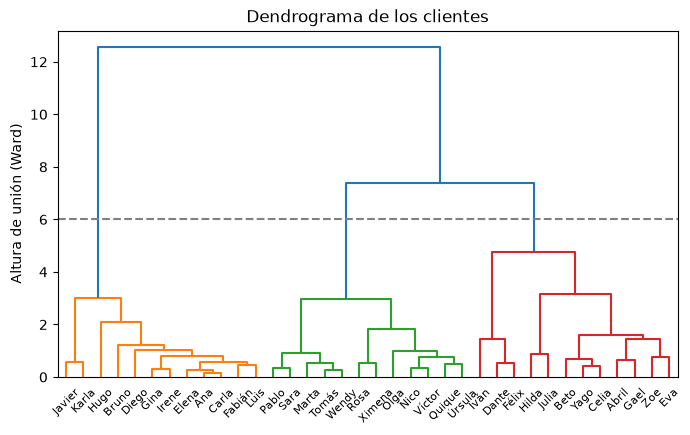

In [6]:
Z = linkage(Z_datos, method="ward")

fig, ax = plt.subplots(figsize=(8, 4.5))
dendrogram(Z, labels=clientes.index.tolist(), leaf_font_size=8, color_threshold=6, ax=ax)
ax.axhline(6, color="gray", linestyle="--")
ax.set_ylabel("Altura de unión (Ward)")
ax.set_title("Dendrograma de los clientes")
plt.show()

## 5. Cortar el dendrograma y elegir k

Una línea horizontal corta el árbol en tantos clústeres como ramas atraviesa. Una regla práctica es cortar donde hay un **salto grande** entre alturas de unión consecutivas: unir esos grupos costaría mucho más que todas las uniones anteriores.

`fcluster` hace el corte de dos maneras:

| `criterion` | `t` significa |
| --- | --- |
| `"maxclust"` | Número máximo de clústeres |
| `"distance"` | Altura del corte |

In [7]:
alturas = Z[-6:, 2][::-1]          # las 6 últimas uniones, de la más alta a la más baja
for k, h in enumerate(alturas, start=1):
    print(f"Pasar de {k + 1} a {k} clústeres cuesta una unión a altura {h:.2f}")

etiquetas_k = fcluster(Z, t=3, criterion="maxclust")
etiquetas_h = fcluster(Z, t=6, criterion="distance")
print("Tamaños con maxclust=3:", np.bincount(etiquetas_k)[1:])
print("Mismo corte por altura 6:", (etiquetas_k == etiquetas_h).all())

Pasar de 2 a 1 clústeres cuesta una unión a altura 12.56
Pasar de 3 a 2 clústeres cuesta una unión a altura 7.39
Pasar de 4 a 3 clústeres cuesta una unión a altura 4.78
Pasar de 5 a 4 clústeres cuesta una unión a altura 3.16
Pasar de 6 a 5 clústeres cuesta una unión a altura 3.00
Pasar de 7 a 6 clústeres cuesta una unión a altura 2.98
Tamaños con maxclust=3: [12 12 12]
Mismo corte por altura 6: True


El hueco más grande entre alturas consecutivas está entre 7.39 y 12.56, lo que sugiere $k = 2$: aficionados a la tecnología frente a lectores. El siguiente hueco, entre 4.78 y 7.39, sugiere $k = 3$, y es donde corta la línea discontinua del dendrograma. La regla del salto es orientativa: la decisión final combina las alturas con la interpretación de los grupos, y en la sección 8 se verá que el tercer grupo (lectores que compran con mucha frecuencia) tiene sentido para el negocio.

## 6. `AgglomerativeClustering` de scikit-learn

scikit-learn implementa el mismo algoritmo con la interfaz habitual `fit_predict`. Las etiquetas empiezan en 0 y su numeración puede diferir de la de SciPy, así que se comparan con una tabla cruzada o con el **índice de Rand ajustado** (ARI), que vale 1 cuando dos particiones coinciden aunque los números de grupo estén permutados.

In [8]:
agrupador = AgglomerativeClustering(n_clusters=3, linkage="ward")
etiquetas_sk = agrupador.fit_predict(Z_datos)

print(pd.crosstab(etiquetas_k, etiquetas_sk, rownames=["SciPy"], colnames=["sklearn"]))
print("ARI SciPy vs sklearn:", adjusted_rand_score(etiquetas_k, etiquetas_sk))

sklearn   0   1   2
SciPy              
1         0  12   0
2         0   0  12
3        12   0   0
ARI SciPy vs sklearn: 1.0


## 7. Comparar criterios de enlace

Como aquí los segmentos verdaderos son conocidos, se puede medir cuánto se parece cada partición a ellos con el ARI.

In [9]:
for metodo in ["single", "complete", "average", "ward"]:
    etiquetas = fcluster(linkage(Z_datos, method=metodo), t=3, criterion="maxclust")
    print(f"{metodo:>8}: tamaños={np.bincount(etiquetas)[1:]}, "
          f"ARI={adjusted_rand_score(clientes['segmento'], etiquetas):.2f}")

  single: tamaños=[12 12 12], ARI=1.00
complete: tamaños=[21  3 12], ARI=0.55
 average: tamaños=[12  3 21], ARI=0.55
    ward: tamaños=[12 12 12], ARI=1.00


En estos datos Ward y el enlace simple recuperan los tres segmentos, mientras que el completo y el promedio juntan a casi todos los lectores en un grupo de 21 y separan un grupo pequeño de 3. El enlace simple funciona aquí porque los grupos están bien separados; cuando hay puntos intermedios entre grupos, su efecto de encadenamiento suele unir clústeres distintos en uno alargado.

## 8. Perfil de los clústeres

Para interpretar los clústeres se calcula la **media de cada variable por grupo** en las unidades originales. El perfil es lo que permite ponerles nombre.

In [10]:
clientes["cluster"] = etiquetas_k
perfil = clientes.groupby("cluster")[variables].mean().round(1)
perfil["n"] = clientes["cluster"].value_counts().sort_index()
perfil

,tecnologia,libros,hogar,compras_mes,n
cluster,,,,,
1,792.0,81.1,370.0,3.3,12
2,178.6,409.8,264.2,2.8,12
3,189.2,384.2,308.9,11.8,12


## 9. Recomendar a partir de los clústeres

Hay dos formas habituales de usar los clústeres para recomendar:

- **Por pertenencia:** se recomienda lo que es popular en el clúster del cliente, es decir, la categoría en la que su grupo gasta más.
- **Por vecino más cercano dentro del clúster:** se busca el cliente del mismo grupo con la menor distancia estandarizada y se recomienda lo que ese cliente compró.

In [11]:
def recomendar(nombre):
    grupo = clientes.loc[nombre, "cluster"]
    miembros = clientes.index[clientes["cluster"] == grupo]
    categoria = perfil.loc[grupo, ["tecnologia", "libros", "hogar"]].idxmax()

    # Vecino más cercano dentro del clúster, con los datos estandarizados
    pos = clientes.index.get_loc(nombre)
    otros = [clientes.index.get_loc(m) for m in miembros if m != nombre]
    dist = np.linalg.norm(Z_datos[otros] - Z_datos[pos], axis=1)
    vecino = clientes.index[otros[dist.argmin()]]
    return grupo, categoria, vecino, dist.min()

for nombre in ["Ana", "Marta", "Zoe"]:
    grupo, categoria, vecino, d = recomendar(nombre)
    print(f"{nombre}: clúster {grupo}, categoría fuerte del grupo = {categoria}, "
          f"cliente más parecido = {vecino} (distancia {d:.2f})")

Ana: clúster 1, categoría fuerte del grupo = tecnologia, cliente más parecido = Carla (distancia 0.17)
Marta: clúster 2, categoría fuerte del grupo = libros, cliente más parecido = Wendy (distancia 0.47)
Zoe: clúster 3, categoría fuerte del grupo = libros, cliente más parecido = Eva (distancia 0.75)


## 10. Errores frecuentes

**No estandarizar.** Con las variables en sus unidades originales, la columna `hogar`, que tiene mucho ruido y valores grandes, domina la distancia, y el número de compras casi no cuenta. Los dos tipos de lectores se mezclan:

In [12]:
sin_estandarizar = fcluster(linkage(clientes[variables], method="ward"), t=3, criterion="maxclust")
print("ARI sin estandarizar:", round(adjusted_rand_score(clientes["segmento"], sin_estandarizar), 2))
print("ARI estandarizado:   ", round(adjusted_rand_score(clientes["segmento"], etiquetas_k), 2))

ARI sin estandarizar: 0.51
ARI estandarizado:    1.0


**Comparar etiquetas con `==`.** Dos métodos pueden encontrar exactamente los mismos grupos con números distintos. Comparar elemento a elemento da un resultado engañoso; el ARI o una tabla cruzada no dependen de la numeración:

In [13]:
permutadas = (etiquetas_k % 3) + 1          # mismos grupos, otros números
print("Coincidencia con ==:", (permutadas == etiquetas_k).mean())
print("ARI:", adjusted_rand_score(etiquetas_k, permutadas))

Coincidencia con ==: 0.0
ARI: 1.0


**Usar Ward con otra distancia.** Ward se define con la suma de cuadrados, que solo tiene sentido con distancia euclidiana. scikit-learn lo rechaza:

In [14]:
try:
    AgglomerativeClustering(n_clusters=3, linkage="ward", metric="manhattan").fit(Z_datos)
except ValueError as error:
    print("ValueError:", error)

ValueError: manhattan was provided as metric. Ward can only work with euclidean distances (i.e. 'euclidean' and 'l2').


**Elegir k sin mirar el dendrograma.** Fijar `n_clusters` de antemano oculta si la estructura de los datos sugiere otro número de grupos. Conviene revisar las alturas de unión, como en la sección 5, antes de decidir.

## 11. Ejercicio

Usa el conjunto `load_iris` de scikit-learn (150 flores, 4 medidas en centímetros), sin mirar la especie para agrupar.

1. Estandariza las cuatro medidas y calcula el enlace de Ward con SciPy.
2. Imprime las alturas de las 5 últimas uniones y elige k según el salto más grande.
3. Corta el árbol en 3 clústeres con `fcluster` y compara con la especie real mediante una tabla cruzada y el ARI.
4. Calcula el perfil (medias en centímetros) de cada clúster.
5. Encuentra la flor más parecida a la flor 0 dentro de su mismo clúster.

### Solución

In [15]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
flores = iris.data
especie = iris.target.map(dict(enumerate(iris.target_names)))

# 1. Estandarizar y enlazar
Z_iris_datos = StandardScaler().fit_transform(flores)
Z_iris = linkage(Z_iris_datos, method="ward")

# 2. Alturas de las últimas uniones
print("Últimas alturas:", Z_iris[-5:, 2][::-1].round(2))

# 3. Corte en 3 clústeres y comparación con la especie
grupos = fcluster(Z_iris, t=3, criterion="maxclust")
print(pd.crosstab(grupos, especie, rownames=["clúster"], colnames=["especie"]))
print("ARI:", round(adjusted_rand_score(especie, grupos), 3))

Últimas alturas: [27.25 12.64  8.    6.61  4.24]
especie  setosa  versicolor  virginica
clúster                               
1            49           0          0
2             1          27          2
3             0          23         48
ARI: 0.615


In [16]:
# 4. Perfil en centímetros
print(flores.groupby(grupos).mean().round(2))

# 5. Vecino más cercano de la flor 0 dentro de su clúster
mismo = np.where(grupos == grupos[0])[0]
mismo = mismo[mismo != 0]
dist = np.linalg.norm(Z_iris_datos[mismo] - Z_iris_datos[0], axis=1)
print(f"Flor más parecida a la 0: {mismo[dist.argmin()]} (distancia {dist.min():.3f})")

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
1               5.02              3.45               1.47              0.24
2               5.53              2.57               3.93              1.21
3               6.55              2.99               5.27              1.85
Flor más parecida a la 0: 17 (distancia 0.132)


El salto más grande (de 12.64 a 27.25) sugiere $k = 2$: setosa frente a las otras dos especies, que se traslapan en sus medidas. Con el corte en 3, el clúster 1 coincide casi exactamente con setosa, mientras que versicolor y virginica se reparten entre los clústeres 2 y 3; por eso el ARI es 0.615 y no 1.

## Resumen

- Las distancias dependen de las escalas: hay que estandarizar antes de agrupar.
- El algoritmo aglomerativo une en cada paso los dos clústeres más cercanos según un criterio de enlace: simple, completo, promedio o Ward.
- Ward une el par que menos aumenta la suma de cuadrados intra-clúster, $\Delta = \frac{n_A n_B}{n_A + n_B}\lVert \mu_A - \mu_B\rVert^2$.
- El dendrograma se corta con `fcluster` donde hay un salto grande de altura; `AgglomerativeClustering` da la misma partición con la interfaz de scikit-learn.
- Las particiones se comparan con el ARI o con tablas cruzadas, nunca con `==`.
- El perfil de medias por grupo da nombre a los clústeres, y la pertenencia o el vecino más cercano dentro del clúster sirven para recomendar.

En el **Módulo 28** se presenta k-means, un método que agrupa a partir de centroides y requiere fijar k desde el inicio.